# Module 5 – Fine-Tuning a Small LLM for Customer-Support FAQs
**Goal:** fine-tune a small language model (**DistilGPT-2, 82 M parameters**) with **LoRA** so that it answers e-commerce customer questions concisely and consistently with a store's policies.

| Deliverable (assignment) | Where in this notebook |
|---|---|
| 1. Cleaned & formatted dataset (JSONL) | Step 2 → `train/val/test.jsonl`, `faq_clean.jsonl` |
| 2. Fine-tuned LLM (checkpoints + inference script) | Steps 4, 7 → `checkpoints/`, `lora_adapter/`, `inference.py` |
| 3. Evaluation (manual + automated) | Step 5 → 10-query base-vs-fine-tuned table, BLEU / ROUGE / embedding similarity / perplexity |
| 4. Short report (README) | Step 8 → auto-generated `README.md` draft |

### Pipeline
`Dataset (JSONL)` → `clean + split` → `DistilGPT-2 + LoRA (PEFT)` → `Trainer + early stopping` → `evaluation (base vs fine-tuned)` → `CLI / Gradio inference`

### Minimal-compute strategy (as required)
* Colab **T4 GPU**, model ≤ 125 M parameters (default `distilgpt2`)
* **LoRA** (only ~1–3 % of the weights are trained) + mixed precision (fp16)
* Optional **8-bit / 4-bit quantisation** switch (`QUANT`) – see Step 3 for the caveat
* 5 epochs, batch size 8, early stopping on validation loss

> **Runtime → Change runtime type → T4 GPU.** Whole notebook ≈ 10 min.

## Step 0 – Setup
Install the libraries. (`transformers`, `torch`, `pandas` are already in Colab; we do **not** upgrade them to avoid version clashes.)

In [1]:
!pip install -q peft accelerate sacrebleu rouge-score sentence-transformers bitsandbytes gradio

  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.8/100.8 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 27.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.7/129.7 kB 9.0 MB/s eta 0:00:00


In [2]:
import os, re, json, random, time, math, inspect, shutil, subprocess, sys, contextlib, unicodedata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers, peft
from transformers import (AutoModelForCausalLM, AutoTokenizer, Trainer, TrainingArguments,
                          EarlyStoppingCallback, BitsAndBytesConfig, set_seed)
from peft import LoraConfig, get_peft_model, PeftModel, prepare_model_for_kbit_training
from IPython.display import display, Markdown

# ------------------------------- configuration ------------------------------
MODEL_NAME   = "distilgpt2"   # <=125M params. Alternatives: "gpt2" (124M), "facebook/opt-125m", "EleutherAI/pythia-70m"
QUANT        = None           # None | "8bit" | "4bit"   (see Step 3 – GPT-2 style layers are not quantised by bitsandbytes)
LORA_R, LORA_ALPHA, LORA_DROPOUT = 32, 64, 0.05
EPOCHS       = 5              # assignment: 3-5 epochs
BATCH_SIZE   = 8              # assignment: batch size 8
LR           = 5e-4
WARMUP_STEPS = 20
PATIENCE     = 2              # early stopping on validation loss
MAX_LEN      = 128            # prompt + answer tokens
MAX_NEW_TOKENS = 64
SEED         = 42
# -----------------------------------------------------------------------------
WORK        = "/content/llm_faq"
DATA_DIR    = f"{WORK}/data"
CKPT_DIR    = f"{WORK}/checkpoints"
ADAPTER_DIR = f"{WORK}/lora_adapter"
MERGED_DIR  = f"{WORK}/merged_model"
OUT_DIR     = f"{WORK}/outputs"
for d in (DATA_DIR, CKPT_DIR, OUT_DIR): os.makedirs(d, exist_ok=True)

set_seed(SEED); random.seed(SEED); np.random.seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__}")
print("device:", device, "|", torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU - please switch to a T4 GPU runtime")

torch 2.11.0+cu130 | transformers 5.20.1 | peft 0.21.2
device: cuda | Tesla T4


## Step 1 – Domain & dataset source
**Domain:** e-commerce customer support for a fictional online store, *ShopEase* (returns, refunds, shipping, payments, accounts, promotions, warranty, …).

The assignment allows us to *collect or synthesise ~500–1000 Q&A pairs*. We synthesise **837 pairs** from **56 policy topics** × several paraphrased questions each. All answers follow **one consistent policy sheet** (e.g. 30-day returns, free shipping over $50, refunds in 5–7 business days). This matters: the base model cannot know these store-specific facts, so any correct answer after fine-tuning is genuinely *learned* from the data.

The generator below is deterministic (seed 42). It writes `ecommerce_faqs.jsonl`:
```json
{"prompt": "How do I track my order?", "response": "You can track your order under My Orders ...", "qid": "track_order_0"}
```
`qid` identifies paraphrases of the same base question; we use it in Step 2 so that paraphrases of one question never end up in different splits (otherwise the test score would be inflated by near-duplicates).

**Using your own data?** Upload a JSONL file called `ecommerce_faqs.jsonl` (keys `prompt` and `response`, `qid` optional) to `/content` *before* running the next-but-one cell and the notebook will use it instead.

In [3]:
%%writefile build_ecommerce_faq_dataset.py
"""Synthetic e-commerce (fictional store "ShopEase") customer-support FAQ generator.

Usage:  python build_ecommerce_faq_dataset.py [out.jsonl] [seed]

Output: JSONL, one object per line:
        {"prompt": "...", "response": "...", "qid": "<question-group id>"}
"prompt"/"response" follow the assignment format. "qid" marks paraphrases of the same base
question so that the notebook can split train/val/test WITHOUT leaking near-duplicates.
All answers are consistent with one fictional policy sheet (30-day returns, free shipping over $50, ...).
"""
import json
import random
import sys

# ---------------------------------------------------------------------------
# (topic_id, [question paraphrases], [answer variants])  -- all facts are fictional
# ---------------------------------------------------------------------------
TOPICS = [
    ("return_window",
     ["Can I return a product after 30 days?", "What is your return policy?", "How long do I have to return an item?",
      "Is there a time limit for returns?", "I bought something 40 days ago, can I still send it back?",
      "Until when can I return my order?"],
     ["Returns are accepted within 30 days of delivery. After that we cannot take the item back, sorry!",
      "You can return items within 30 days of delivery. Once the 30 days are over, returns are no longer possible."]),
    ("return_condition",
     ["What condition must an item be in to be returned?", "Can I return something I have already used?",
      "Do I need the original packaging to return a product?", "Can I return an item without the tags?",
      "Do you accept opened products for return?", "What are the requirements for a return?"],
     ["Items must be unused, in their original packaging and with all tags attached to be eligible for a return.",
      "To be returned, an item has to be unused and in its original packaging with the tags still on."]),
    ("return_how",
     ["How do I return an item?", "How can I start a return?", "What is the process to send something back?",
      "Where do I request a return?", "I want to return my order, what do I do?", "How do I get a return label?"],
     ["Go to My Orders, select the item and click Return Item. You will get a return label by email within a few minutes.",
      "Start the return in My Orders by choosing Return Item. We then email you a printable return label."]),
    ("refund_time",
     ["How long does a refund take?", "When will I get my money back?", "How many days until my refund arrives?",
      "I returned my item, when do I get the refund?", "How fast are refunds processed?",
      "Where does my refund go?"],
     ["Refunds are issued to your original payment method within 5-7 business days after we receive the returned item.",
      "Once we receive your return, the refund goes back to your original payment method in 5-7 business days."]),
    ("return_shipping_cost",
     ["Who pays for return shipping?", "Is return shipping free?", "How much does it cost to send an item back?",
      "Do I have to pay to return a product?", "Are there any return fees?", "What is the return label fee?"],
     ["Return shipping costs $5.99, deducted from your refund. It is free if the item is defective, damaged or the wrong one.",
      "A $5.99 return shipping fee is deducted from your refund, unless the item arrived defective, damaged or incorrect, then it is free."]),
    ("exchange",
     ["Can I exchange an item for a different size?", "Do you offer exchanges?", "I ordered the wrong colour, can I swap it?",
      "How do I exchange a product?", "Is there a fee for exchanges?", "Can I get a different size instead of a refund?"],
     ["Yes, size and colour exchanges are free within 30 days of delivery. Start one from My Orders by choosing Exchange Item.",
      "We offer free size and colour exchanges within 30 days of delivery. Choose Exchange Item in My Orders to begin."]),
    ("final_sale",
     ["Which items cannot be returned?", "Are sale items returnable?", "Can I return a gift card?",
      "Can personalised products be returned?", "What does Final Sale mean?", "Are there any non-returnable products?"],
     ["Items marked Final Sale, gift cards and personalised products cannot be returned or exchanged.",
      "Final Sale items, gift cards and personalised products are not eligible for return or exchange."]),
    ("damaged_item",
     ["My item arrived damaged, what should I do?", "I received a broken product.", "The package was damaged when it arrived, can you help?",
      "What if my order is defective?", "How do I report a damaged item?", "My product does not work, what now?"],
     ["We are sorry about that! Report it within 48 hours of delivery with a photo through My Orders and we will send a free replacement or a refund.",
      "Please report damaged or defective items within 48 hours of delivery and attach a photo in My Orders. We will replace it or refund you for free."]),
    ("wrong_item",
     ["I received the wrong item, what do I do?", "You sent me the wrong product.", "The item in my package is not what I ordered.",
      "How do I report an incorrect item?", "I got someone else's order, help!", "My order has the wrong size, can you fix it?"],
     ["Sorry for the mix-up! Contact support with your order number and a photo and we will ship the correct item free of charge with a prepaid return label.",
      "Please send us your order number and a photo. We will ship the correct item at no cost and include a prepaid label for the wrong one."]),
    ("missing_package",
     ["My tracking says delivered but I did not get my package.", "Where is my package? It says delivered.", "I never received my order.",
      "My parcel is marked as delivered but it is not here.", "What do I do if my package is lost?", "The courier says delivered, but I see nothing."],
     ["Please wait 24 hours and check with neighbours, as carriers sometimes mark parcels early. If it still has not arrived, contact support within 7 days and we will investigate.",
      "Give it 24 hours and ask your neighbours first. If the package is still missing, contact support within 7 days so we can open an investigation."]),
    ("track_order",
     ["How do I track my order?", "Where can I see my order status?", "Where is my order?", "How can I check where my package is?",
      "Can I get a tracking number?", "I want to follow my delivery."],
     ["You can track your order under My Orders by clicking Track. We also email you a tracking link as soon as it ships.",
      "Open My Orders and click Track next to your order. A tracking link is also sent to you by email once the order ships."]),
    ("processing_time",
     ["How long does it take to process my order?", "When will my order ship?", "How soon do you dispatch orders?",
      "My order still says processing, is that normal?", "How many days until my order is shipped?", "What does processing mean?"],
     ["Orders are processed within 1 business day. Once shipped, you receive a confirmation email with tracking details.",
      "We process orders in 1 business day and then email you a shipping confirmation with tracking information."]),
    ("cancel_order",
     ["How do I cancel my order?", "Can I cancel an order I just placed?", "I want to cancel my purchase.",
      "Is it possible to cancel after ordering?", "What if my order already shipped and I want to cancel?", "Where is the cancel button?"],
     ["You can cancel for free from My Orders until the order has shipped. If it has already shipped, refuse the delivery or return it within 30 days.",
      "Open My Orders and click Cancel as long as the order has not shipped. Shipped orders can be returned within 30 days instead."]),
    ("change_address",
     ["Can I change my delivery address?", "I entered the wrong shipping address, what can I do?", "How do I update the address on my order?",
      "Can I change my address after placing the order?", "Can you ship my order to a different address?", "I moved, can I edit the delivery address?"],
     ["You can edit the address in My Orders before the order ships. Once it has shipped, the address can no longer be changed.",
      "The delivery address can be changed in My Orders until the order ships. After shipping it is not possible to change it."]),
    ("modify_order",
     ["Can I add an item to my order?", "Can I change the items in my order?", "I forgot something, can I add it to my existing order?",
      "How do I change the quantity after ordering?", "Can I edit my order after checkout?", "Can I remove an item from my order?"],
     ["Orders cannot be edited after checkout. Please cancel the order in My Orders before it ships and place a new one.",
      "Once placed, an order cannot be modified. Cancel it from My Orders before it ships and reorder with the right items."]),
    ("standard_shipping",
     ["How long does standard shipping take?", "What are your delivery times?", "How much is standard delivery?",
      "How many days will my order take to arrive?", "What does regular shipping cost?", "When will I receive my package?"],
     ["Standard shipping takes 3-5 business days and costs $4.99.",
      "Standard delivery costs $4.99 and arrives within 3-5 business days."]),
    ("free_shipping",
     ["Is there free delivery?", "Do you offer free shipping?", "What is the minimum order for free shipping?",
      "How much do I need to spend to get free shipping?", "Is shipping free on all orders?", "Do orders over $50 ship free?"],
     ["Yes! Standard shipping is free on orders over $50.",
      "Standard shipping is free for orders above $50. Smaller orders pay $4.99."]),
    ("express_shipping",
     ["Do you have express shipping?", "How fast is express delivery?", "How much does express shipping cost?",
      "I need my order quickly, what are my options?", "Can I get next-day delivery?", "What is the cutoff time for express orders?"],
     ["Express shipping costs $12.99 and delivers in 1-2 business days. Order before 2 pm ET to ship the same day.",
      "Yes, express shipping is $12.99 with delivery in 1-2 business days. Orders placed before 2 pm ET ship the same day."]),
    ("international",
     ["Do you ship internationally?", "Do you ship to Canada?", "Can I order from outside the US?",
      "How long does international shipping take?", "Do I pay customs duties on international orders?", "Which countries do you deliver to?"],
     ["We ship to over 40 countries. International delivery takes 7-14 business days and any customs duties or import taxes are paid by the customer.",
      "Yes, we deliver to 40+ countries in 7-14 business days. Customs duties and import taxes are the customer's responsibility."]),
    ("po_box",
     ["Can you ship to a PO box?", "Do you deliver to post office boxes?", "Is express shipping available for P.O. boxes?",
      "Can I use a PO box as a delivery address?", "Do you deliver to parcel lockers?", "Can I ship to an APO address?"],
     ["Standard shipping works for PO boxes, but express shipping needs a street address.",
      "Yes, standard orders can go to a PO box. Express orders require a street address."]),
    ("weekend_delivery",
     ["Do you deliver on weekends?", "Is Sunday delivery available?", "Can my order arrive on a Saturday?",
      "Do business days include weekends?", "Do you ship on holidays?", "What days do you deliver?"],
     ["We deliver Monday to Saturday. There is no Sunday or holiday delivery, and business days do not include weekends.",
      "Deliveries happen Monday through Saturday. We do not deliver on Sundays or holidays, and weekends are not counted as business days."]),
    ("payment_methods",
     ["What payment methods do you accept?", "Can I pay with PayPal?", "Do you take American Express?",
      "Is Apple Pay accepted?", "Which cards can I use at checkout?", "Can I pay with a gift card?"],
     ["We accept Visa, MasterCard, American Express, PayPal, Apple Pay and ShopEase gift cards.",
      "You can pay with Visa, MasterCard, American Express, PayPal, Apple Pay or a ShopEase gift card."]),
    ("payment_declined",
     ["Why was my card declined?", "My payment failed, what should I do?", "Checkout will not accept my credit card.",
      "I get a payment error at checkout.", "My card keeps getting rejected.", "What do I do if my payment is declined?"],
     ["Please check your card number, expiry date and billing address. If everything is correct, contact your bank or try another payment method.",
      "Double-check the card details and billing address first. If it still fails, call your bank or use a different payment method."]),
    ("cod",
     ["Do you offer cash on delivery?", "Can I pay when the order arrives?", "Is COD available?",
      "Can I pay by bank transfer?", "Can I pay in instalments?", "Can I pay with cash?"],
     ["Sorry, cash on delivery is not available. Please pay online with a card, PayPal, Apple Pay or a gift card.",
      "We do not offer cash on delivery. You can pay online by card, PayPal, Apple Pay or gift card."]),
    ("promo_code",
     ["How do I use a promo code?", "Where do I enter my discount code?", "Can I use two coupons on one order?",
      "My coupon code is not working.", "Can promo codes be combined?", "How do I apply a voucher?"],
     ["Enter your code in the Promo Code box at checkout and click Apply. Only one code can be used per order and codes cannot be combined.",
      "Type the code into the Promo Code field at checkout. Each order accepts one code, and codes cannot be combined."]),
    ("welcome_discount",
     ["Do you have a discount for new customers?", "Is there a first order discount?", "How do I get 10% off?",
      "What is the welcome code?", "Do you have a newsletter discount?", "Can I get a coupon for signing up?"],
     ["Yes! Subscribe to our newsletter and use the code WELCOME10 for 10% off your first order.",
      "New customers get 10% off their first order with the code WELCOME10 after subscribing to our newsletter."]),
    ("gift_cards",
     ["Do gift cards expire?", "How do I redeem a gift card?", "How can I check my gift card balance?",
      "Can I buy a gift card for a friend?", "Where do I enter my gift card code?", "Is there an expiry date on gift cards?"],
     ["ShopEase gift cards never expire. Enter the code at checkout and check your balance under Account > Gift Cards.",
      "Gift cards do not expire. Redeem them by entering the code at checkout, and view the balance in Account > Gift Cards."]),
    ("price_adjustment",
     ["The price dropped after I bought it, can I get a refund of the difference?", "Do you offer price matching?", "Can I get a price adjustment?",
      "The item I bought is on sale now, what can I do?", "Do you refund price drops?", "What is your price adjustment policy?"],
     ["If the price drops within 14 days of your purchase, contact support with your order number and we will refund the difference.",
      "We offer price adjustments within 14 days of purchase. Contact support with your order number and we will refund the difference."]),
    ("invoice",
     ["Where can I find my invoice?", "Can I get a receipt for my order?", "How do I download my invoice?",
      "I need an invoice for my company.", "Do you send receipts by email?", "Where is my order receipt?"],
     ["Your invoice is emailed with the order confirmation and can be downloaded anytime from My Orders.",
      "We email the invoice together with your order confirmation. You can also download it from My Orders."]),
    ("sales_tax",
     ["Do you charge sales tax?", "How is tax calculated on my order?", "Why was I charged tax?",
      "Are prices tax inclusive?", "Where can I see the tax amount?", "Is VAT included in the price?"],
     ["Sales tax is calculated at checkout based on your shipping address and shown before you pay.",
      "Tax is added at checkout according to your delivery address, and the exact amount is displayed before you place the order."]),
    ("reset_password",
     ["I forgot my password, help!", "How do I reset my password?", "I cannot log in to my account.",
      "How can I change my password?", "I did not receive the password reset email.", "Where is the forgot password link?"],
     ["Click Forgot Password on the login page and enter your email. We will send a reset link, so please check your spam folder if you do not see it.",
      "Use the Forgot Password link on the login page. A reset link is emailed to you, and it may land in your spam folder."]),
    ("change_email",
     ["How do I change my email address?", "Can I update my account email?", "I want to use a different email for my account.",
      "Where do I edit my profile details?", "How do I change my phone number?", "Can I change my name on my account?"],
     ["Go to Account Settings > Profile to update your email address, phone number or name.",
      "You can edit your email, phone number and name under Account Settings > Profile."]),
    ("delete_account",
     ["How do I delete my account?", "Can I close my account?", "I want my data removed.",
      "How can I deactivate my profile?", "Can you delete my personal information?", "I no longer want an account with you."],
     ["Email support@shopease.example from your registered address to request deletion. Your account and data are removed within 5 business days.",
      "To delete your account, send a request to support@shopease.example from your registered email. It is processed within 5 business days."]),
    ("guest_checkout",
     ["Do I need an account to order?", "Can I check out as a guest?", "Is it necessary to register?",
      "Why should I create an account?", "Can I buy without signing up?", "Do I have to log in to place an order?"],
     ["No, guest checkout is available. An account is optional but lets you track orders, save addresses and earn reward points.",
      "You can check out as a guest. Creating an account is optional, but it lets you track orders and earn rewards."]),
    ("two_factor",
     ["How do I enable two-factor authentication?", "Can I make my account more secure?", "Do you support 2FA?",
      "Where are the security settings?", "How do I turn on login verification?", "Is my account protected with a second step?"],
     ["Yes, turn on two-factor authentication in Account Settings > Security. You will then confirm each login with a code sent to your phone.",
      "We support two-factor authentication. Enable it in Account Settings > Security and confirm logins with a code sent to your phone."]),
    ("account_locked",
     ["My account is locked, what do I do?", "Why can't I log in after several attempts?", "How long is my account locked?",
      "I entered the wrong password too many times.", "It says my account has been temporarily locked.", "How do I unlock my account?"],
     ["After 5 failed login attempts the account is locked for 30 minutes. Wait, or reset your password with Forgot Password to get back in right away.",
      "Five wrong passwords lock the account for 30 minutes. You can wait or use Forgot Password to reset it immediately."]),
    ("warranty",
     ["Do your products have a warranty?", "How long is the warranty on electronics?", "How do I make a warranty claim?",
      "My headphones stopped working after 6 months, is it covered?", "What does the warranty cover?", "Is there a guarantee on electronics?"],
     ["Electronics come with a 1-year manufacturer warranty. To make a claim, contact support with your order number and a description of the problem.",
      "All electronics are covered by a 1-year manufacturer warranty. Contact support with your order number to start a claim."]),
    ("out_of_stock",
     ["The item is out of stock, when will it be back?", "Can I be notified when a product is available again?", "What does sold out mean?",
      "When will you restock?", "How do I get a restock alert?", "Why is my size unavailable?"],
     ["Click Notify Me on the product page and we will email you when it is back. Restocks usually take 2-3 weeks.",
      "Use the Notify Me button on the product page for a restock email. Items are typically back in 2-3 weeks."]),
    ("preorder",
     ["How do pre-orders work?", "When am I charged for a pre-order?", "Can I pre-order an item?",
      "When will my pre-order ship?", "Can I cancel a pre-order?", "What is a pre-order?"],
     ["Pre-ordered items are charged when they ship, and they ship on the release date shown on the product page. You can cancel any time before shipping.",
      "You are charged only when a pre-order ships on its release date, and you can cancel it at any time before then."]),
    ("authentic",
     ["Are your products authentic?", "Do you sell original brands?", "Can I trust that the items are genuine?",
      "Are your products fake or original?", "Where do you source your products?", "Is this a genuine product?"],
     ["Yes, every product is sourced directly from authorised brands and suppliers, so all items are 100% authentic.",
      "All our products come from authorised brands and suppliers and are guaranteed authentic."]),
    ("size_guide",
     ["How do I find my size?", "Where is the size chart?", "Do your clothes run small?",
      "Is there a size guide?", "Which size should I order?", "How do I measure myself?"],
     ["Every product page has a Size Guide link next to the size selector with measurements. If you are between sizes, we recommend sizing up.",
      "Use the Size Guide link beside the size selector on each product page. If you are between two sizes, size up."]),
    ("rewards",
     ["How do reward points work?", "How many points do I earn per dollar?", "Do reward points expire?",
      "How do I redeem my points?", "What is ShopEase Rewards?", "How much is 100 points worth?"],
     ["With ShopEase Rewards you earn 1 point per $1 spent, and 100 points equal $5 off. Points expire after 12 months of account inactivity.",
      "You earn 1 point for every $1 spent, and every 100 points are worth $5 off at checkout. Points expire after 12 months without activity."]),
    ("contact_support",
     ["How can I contact customer support?", "What is your support email?", "Do you have live chat?",
      "How long until I get a reply from support?", "Where can I talk to a person?", "How do I reach your team?"],
     ["Email support@shopease.example or use live chat daily from 9 am to 9 pm ET. We reply to emails within 24 hours.",
      "Reach us at support@shopease.example or through live chat from 9 am to 9 pm ET every day. Email replies take up to 24 hours."]),
    ("phone_support",
     ["Do you have a phone number?", "Can I call customer service?", "What are your phone support hours?",
      "Is there a hotline?", "I would rather speak to someone by phone.", "What number do I call for help?"],
     ["Yes, call 1-800-555-0199 Monday to Friday, 9 am to 6 pm ET.",
      "You can call us on 1-800-555-0199 from Monday to Friday, between 9 am and 6 pm ET."]),
    ("physical_store",
     ["Do you have a physical store?", "Can I pick up my order in person?", "Where are your shops located?",
      "Can I visit your showroom?", "Is there a store near me?", "Do you offer in-store pickup?"],
     ["ShopEase is an online-only store, so we have no physical shops or in-store pickup. Everything is delivered to your door.",
      "We are online only. There are no physical stores or pickup points, and every order is delivered to your address."]),
    ("bulk_orders",
     ["Do you offer bulk discounts?", "I want to order in large quantities.", "Can businesses buy in bulk?",
      "Is there a wholesale price?", "I need 50 units, can I get a deal?", "Do you offer corporate orders?"],
     ["For orders of 10 or more items, email bulk@shopease.example and our team will send you a custom quote.",
      "Bulk and corporate orders of 10+ items get special pricing. Write to bulk@shopease.example for a quote."]),
    ("gift_wrap",
     ["Do you offer gift wrapping?", "Can I add a gift message?", "How much is gift wrap?",
      "Can you send my order as a gift?", "How do I add a card to my gift?", "Can I hide the price on a gift order?"],
     ["Yes, gift wrap costs $3.99 per item. Select it at checkout, where you can also add a message card and the invoice will not show prices.",
      "Gift wrapping is $3.99 per item. Choose it at checkout to add a personal message, and prices are left off the packing slip."]),
    ("privacy",
     ["Is my personal data safe?", "Do you sell my information?", "How do you protect my payment details?",
      "What do you do with my data?", "Is it safe to enter my card on your site?", "Do you share my details with third parties?"],
     ["We never sell your personal information, and all payments are encrypted. You can read the full details in our Privacy Policy.",
      "Your data is not sold to anyone, and payments are protected with encryption. See our Privacy Policy for the details."]),
    ("unsubscribe",
     ["How do I unsubscribe from your emails?", "I want to stop receiving promotional emails.", "Can I opt out of the newsletter?",
      "Too many emails, how do I turn them off?", "Where are the email preferences?", "How can I stop marketing messages?"],
     ["Click the Unsubscribe link at the bottom of any email, or change your choices in Account Settings > Email Preferences.",
      "Use the Unsubscribe link in any of our emails or update Account Settings > Email Preferences."]),
    ("reviews",
     ["How do I write a product review?", "Can I leave a review?", "Where can I rate my purchase?",
      "Why can't I review this item?", "Can I edit my review?", "Are the reviews real?"],
     ["After delivery, open My Orders and click Write a Review. Only verified buyers can review, and you can edit your review at any time.",
      "You can review an item from My Orders once it is delivered. Reviews come from verified buyers and can be edited later."]),
    ("no_confirmation_email",
     ["I did not receive an order confirmation email.", "Where is my confirmation email?", "Can you resend my order confirmation?",
      "I placed an order but got no email.", "My order email never arrived.", "How do I know my order went through?"],
     ["Check your spam folder first. You can also see the order in My Orders and resend the confirmation from there, or contact support if it is missing.",
      "Look in your spam folder, then check My Orders where you can resend the confirmation. If the order is not listed, contact support."]),
    ("split_shipments",
     ["Why did my order arrive in two packages?", "Will my items ship together?", "I only received part of my order.",
      "Why do I have two tracking numbers?", "Can you ship everything in one box?", "Part of my order is missing."],
     ["Orders can ship in separate packages from different warehouses, and each package has its own tracking number. You are not charged extra shipping for it.",
      "Items may ship separately from different warehouses, each with its own tracking number, at no extra shipping cost."]),
    ("delivery_delay",
     ["My order is late, what should I do?", "Why is my delivery delayed?", "My package has not moved for days.",
      "It has been 10 days and my order has not arrived.", "Can you check on my late delivery?", "My tracking has not updated."],
     ["Sorry about the delay! If your order is more than 7 days late, contact support with your order number and we will investigate with the carrier.",
      "We apologise for the delay. If it is over 7 days late, send support your order number and we will look into it with the carrier."]),
    ("mobile_app",
     ["Do you have a mobile app?", "Is there a ShopEase app for iPhone?", "Can I shop on my phone?",
      "Where can I download the app?", "Is the Android app available?", "Do I need a separate account for the app?"],
     ["Yes, the ShopEase app is available for iOS and Android. It uses the same account as the website.",
      "You can download the ShopEase app on iOS and Android and sign in with your usual account."]),
    ("out_of_scope",
     ["What is the weather today?", "Can you tell me a joke?", "What is the capital of France?",
      "Who won the football match yesterday?", "Can you give me medical advice?", "Write me a poem about the sea."],
     ["Sorry, I can only help with ShopEase orders, shipping, returns, payments and accounts. For anything else please contact support@shopease.example.",
      "I am the ShopEase support assistant, so I can only answer questions about orders, shipping, returns, payments and accounts."]),
    ("human_agent",
     ["Can I speak to a human?", "I want to talk to an agent.", "This is not helpful, connect me to support.",
      "How do I escalate my complaint?", "I want to file a complaint.", "Can a manager call me back?"],
     ["Of course. Start a live chat from 9 am to 9 pm ET or email support@shopease.example and a team member will take over.",
      "Sure, you can reach a human agent through live chat (9 am to 9 pm ET) or by emailing support@shopease.example."]),
]

PREFIXES = ["Hi, ", "Hello, ", "Hey, ", "Quick question: ", "Excuse me, ", "Hi there! ", "Good morning, "]
SUFFIXES = [" Thanks!", " Please help.", " Thank you.", " Any info would be appreciated.", " Thanks in advance."]


def decap(q):
    """Lower-case the first letter unless it is a pronoun 'I' or the store name."""
    if q.startswith(("I ", "I'", "ShopEase")):
        return q
    return q[0].lower() + q[1:]


def make_variants(q, rng):
    variants = [q]
    kinds = rng.sample(["prefix", "suffix", "both", "lower"], 1 + int(rng.random() < 0.5))
    for k in kinds:
        if k == "prefix":
            variants.append(rng.choice(PREFIXES) + decap(q))
        elif k == "suffix":
            variants.append(q + rng.choice(SUFFIXES))
        elif k == "both":
            variants.append(rng.choice(PREFIXES) + decap(q) + rng.choice(SUFFIXES))
        else:
            variants.append(q.lower().rstrip("?!. "))
    return variants


def build(seed=42):
    rng = random.Random(seed)
    rows, seen = [], set()
    for topic, questions, answers in TOPICS:
        for k, q in enumerate(questions):
            answer = rng.choice(answers)            # same answer for all paraphrases of one base question
            for v in make_variants(q, rng):
                key = v.lower()
                if key in seen:
                    continue
                seen.add(key)
                rows.append({"prompt": v, "response": answer, "qid": f"{topic}_{k}"})
    rng.shuffle(rows)
    return rows


if __name__ == "__main__":
    out = sys.argv[1] if len(sys.argv) > 1 else "ecommerce_faqs.jsonl"
    seed = int(sys.argv[2]) if len(sys.argv) > 2 else 42
    data = build(seed)
    with open(out, "w", encoding="utf-8") as f:
        for r in data:
            f.write(json.dumps(r, ensure_ascii=False) + "\n")
    print(f"wrote {len(data)} Q&A pairs ({len(TOPICS)} topics, {len({r['qid'] for r in data})} base questions) to {out}")

Writing build_ecommerce_faq_dataset.py


In [4]:
DATA_PATH = "ecommerce_faqs.jsonl"          # looked up in /content
if not os.path.exists(DATA_PATH):
    print("No dataset file found -> generating it with build_ecommerce_faq_dataset.py")
    res = subprocess.run([sys.executable, "build_ecommerce_faq_dataset.py", DATA_PATH], capture_output=True, text=True)
    print(res.stdout, res.stderr)
else:
    print("Using the existing file:", DATA_PATH)
!head -n 3 ecommerce_faqs.jsonl

No dataset file found -> generating it with build_ecommerce_faq_dataset.py
wrote 837 Q&A pairs (56 topics, 336 base questions) to ecommerce_faqs.jsonl
 
{"prompt": "Hey, how do I unlock my account?", "response": "Five wrong passwords lock the account for 30 minutes. You can wait or use Forgot Password to reset it immediately.", "qid": "account_locked_5"}
{"prompt": "do you have a mobile app", "response": "You can download the ShopEase app on iOS and Android and sign in with your usual account.", "qid": "mobile_app_0"}
{"prompt": "Can I use a PO box as a delivery address?", "response": "Yes, standard orders can go to a PO box. Express orders require a street address.", "qid": "po_box_3"}


## Step 2 – Cleaning, formatting and splitting (Deliverable 1)
Cleaning steps applied to every pair:
1. Unicode normalisation (NFKC), removal of control characters, whitespace collapsing
2. Removal of empty rows
3. Length filter: question 2–60 words, answer 3–80 words (keeps answers concise)
4. Removal of rows where question = answer, and of duplicate questions (case-insensitive)

Then an **80 / 10 / 10 split grouped by `qid`**, saved as JSONL in the `{"prompt", "response"}` format required by the assignment.

In [5]:
def load_jsonl(path):
    with open(path, encoding="utf-8") as f:
        return [json.loads(l) for l in f if l.strip()]

def write_jsonl(rows, path):
    with open(path, "w", encoding="utf-8") as f:
        for r in rows: f.write(json.dumps(r, ensure_ascii=False) + "\n")

raw_df = pd.DataFrame(load_jsonl(DATA_PATH))
assert {"prompt", "response"} <= set(raw_df.columns), "JSONL needs the keys 'prompt' and 'response'"
if "qid" not in raw_df.columns:                      # user-supplied data without paraphrase groups
    raw_df["qid"] = np.arange(len(raw_df)).astype(str)

def clean_text(s):
    s = unicodedata.normalize("NFKC", str(s))
    s = re.sub(r"[\x00-\x1f\x7f]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df = raw_df.copy(); clean_log = [("raw pairs", len(df))]
df["prompt"], df["response"] = df["prompt"].map(clean_text), df["response"].map(clean_text)
df = df[(df["prompt"] != "") & (df["response"] != "")];                     clean_log.append(("after removing empty rows", len(df)))
nw_p, nw_r = df["prompt"].str.split().str.len(), df["response"].str.split().str.len()
df = df[nw_p.between(2, 60) & nw_r.between(3, 80)];                         clean_log.append(("after length filter", len(df)))
df = df[df["prompt"].str.lower() != df["response"].str.lower()];            clean_log.append(("after removing prompt==response", len(df)))
df = df.assign(_k=df["prompt"].str.lower()).drop_duplicates("_k").drop(columns="_k").reset_index(drop=True)
clean_log.append(("after de-duplication", len(df)))
display(pd.DataFrame(clean_log, columns=["step", "pairs"]))

# ---- grouped 80/10/10 split (paraphrases of one question stay together) ----
rng = np.random.RandomState(SEED)
qids = np.array(sorted(df["qid"].astype(str).unique())); rng.shuffle(qids)
n_test, n_val = max(1, int(0.10 * len(qids))), max(1, int(0.10 * len(qids)))
test_q, val_q = set(qids[:n_test]), set(qids[n_test:n_test + n_val])
df["qid"] = df["qid"].astype(str)
df["split"] = np.where(df["qid"].isin(test_q), "test", np.where(df["qid"].isin(val_q), "val", "train"))

train_df, val_df, test_df = [df[df.split == s].reset_index(drop=True) for s in ("train", "val", "test")]
assert not (set(train_df.qid) & set(test_df.qid)) and not (set(train_df.qid) & set(val_df.qid)), "leakage between splits"
for name, d in (("train", train_df), ("val", val_df), ("test", test_df)):
    write_jsonl(d[["prompt", "response"]].to_dict("records"), f"{DATA_DIR}/{name}.jsonl")
write_jsonl(df[["prompt", "response"]].to_dict("records"), f"{DATA_DIR}/faq_clean.jsonl")
print(f"train {len(train_df)} | val {len(val_df)} | test {len(test_df)}   (saved to {DATA_DIR})")
display(train_df[["prompt", "response"]].sample(5, random_state=1).style.set_properties(**{"text-align": "left"}))

,step,pairs
0,raw pairs,837
1,after removing empty rows,837
2,after length filter,837
3,after removing prompt==response,837
4,after de-duplication,837


train 671 | val 85 | test 81   (saved to /content/llm_faq/data)


,prompt,response
107,Hi there! what are your phone support hours?,"You can call us on 1-800-555-0199 from Monday to Friday, between 9 am and 6 pm ET."
422,"Hey, is there an expiry date on gift cards? Please help.",ShopEase gift cards never expire. Enter the code at checkout and check your balance under Account > Gift Cards.
111,"Excuse me, how can I check where my package is?",You can track your order under My Orders by clicking Track. We also email you a tracking link as soon as it ships.
544,Can I pay with cash?,"Sorry, cash on delivery is not available. Please pay online with a card, PayPal, Apple Pay or a gift card."
59,Do you share my details with third parties?,"Your data is not sold to anyone, and payments are protected with encryption. See our Privacy Policy for the details."


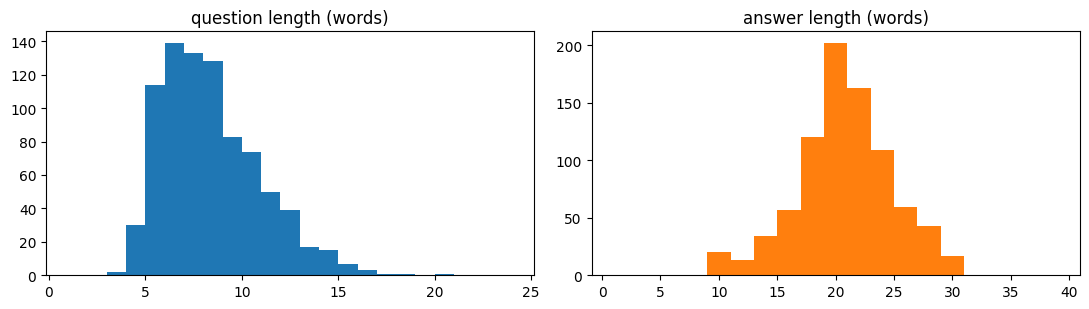

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].hist(df["prompt"].str.split().str.len(), bins=range(1, 25), color="tab:blue");   ax[0].set_title("question length (words)")
ax[1].hist(df["response"].str.split().str.len(), bins=range(1, 40, 2), color="tab:orange"); ax[1].set_title("answer length (words)")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_dataset_lengths.png", dpi=150); plt.show()

## Step 3 – Model selection, prompt format and LoRA
**Base model:** `distilgpt2` (82 M parameters, ≤ 125 M as required).

**Prompt format.** The model is trained as a plain causal LM on
```
Customer: <question>
Support: <answer><eos>
```
The loss is computed **only on the answer tokens** (question tokens are masked with `-100`), so the model learns *to answer* rather than to reproduce questions.

**LoRA** adds small trainable low-rank matrices to the attention and MLP projections and freezes everything else. We first load the *untouched* base model and look at its zero-shot behaviour, then wrap it with LoRA.

**Quantisation note.** `QUANT="8bit"/"4bit"` loads the base weights with bitsandbytes (QLoRA). GPT-2 family models use `Conv1D` layers, which bitsandbytes does **not** quantise, so for `distilgpt2` this has no effect and the 82 M model fits easily in fp32 anyway. To really see quantisation, switch to a model with ordinary `Linear` layers such as `facebook/opt-125m` (the LoRA target modules are chosen automatically).

In [7]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token

bnb_cfg = None
if QUANT == "8bit":
    bnb_cfg = BitsAndBytesConfig(load_in_8bit=True)
elif QUANT == "4bit":
    bnb_cfg = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True,
                                 bnb_4bit_compute_dtype=torch.float16)

if bnb_cfg is not None:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, quantization_config=bnb_cfg, device_map={"": 0})
    model = prepare_model_for_kbit_training(model)
else:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)

n_params = sum(p.numel() for p in model.parameters())
print(f"{MODEL_NAME}: {n_params/1e6:.1f} M parameters (limit 125 M) | model_type = {model.config.model_type}")
assert n_params <= 125e6 * 1.02, "model is larger than the assignment's 125M limit"

def build_prompt(query):
    return f"Customer: {query.strip()}\nSupport:"

@torch.no_grad()
def generate_answers(model, queries, use_adapter=True, max_new_tokens=MAX_NEW_TOKENS, bs=16):
    """Greedy decoding (same settings for base and fine-tuned model). Returns the first line of the generated text."""
    model.eval()
    old_side, tokenizer.padding_side = tokenizer.padding_side, "left"
    outs = []
    ctx = model.disable_adapter() if (not use_adapter and hasattr(model, "disable_adapter")) else contextlib.nullcontext()
    with ctx:
        for i in range(0, len(queries), bs):
            enc = tokenizer([build_prompt(q) for q in queries[i:i + bs]], return_tensors="pt", padding=True).to(model.device)
            gen = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, num_beams=1,
                                 no_repeat_ngram_size=4, use_cache=True, pad_token_id=tokenizer.eos_token_id)
            for row in gen[:, enc["input_ids"].shape[1]:]:
                outs.append(tokenizer.decode(row, skip_special_tokens=True).split("\n")[0].strip())
    tokenizer.padding_side = old_side
    return outs

# ---- zero-shot behaviour of the BASE model (before any fine-tuning) ----
for q in ["Can I return a product after 30 days?", "How do I track my order?", "Do you ship to Canada?"]:
    print("Q:", q, "\nBASE:", generate_answers(model, [q])[0], "\n")

config.json:   0%|          | 0.00/762 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  353MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

distilgpt2: 81.9 M parameters (limit 125 M) | model_type = gpt2
Q: Can I return a product after 30 days? 
BASE:  

Q: How do I track my order? 
BASE:  

Q: Do you ship to Canada? 
BASE:  



In [9]:
# Uninstall torchao to resolve the incompatible version conflict with PEFT
!pip uninstall -y torchao

Found existing installation: torchao 0.10.0
Uninstalling torchao-0.10.0:
  Successfully uninstalled torchao-0.10.0


In [10]:
def lora_target_modules(m):
    t = m.config.model_type
    if t == "gpt2":      return ["c_attn", "c_proj", "c_fc"]
    if t == "opt":       return ["q_proj", "k_proj", "v_proj", "out_proj", "fc1", "fc2"]
    if t == "gpt_neox":  return ["query_key_value", "dense", "dense_h_to_4h", "dense_4h_to_h"]
    if t in ("llama", "mistral", "qwen2", "gemma"): return ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]
    return "all-linear"

lora_cfg = LoraConfig(r=LORA_R, lora_alpha=LORA_ALPHA, lora_dropout=LORA_DROPOUT, bias="none", task_type="CAUSAL_LM",
                      target_modules=lora_target_modules(model), fan_in_fan_out=(model.config.model_type == "gpt2"))
model = get_peft_model(model, lora_cfg)
model.print_trainable_parameters()

trainable params: 2,359,296 || all params: 84,271,872 || trainable%: 2.7996


## Step 4 – Fine-tuning (Hugging Face `Trainer`)
* Tokenise `prompt + answer + <eos>`, mask the prompt part of the labels, pad dynamically per batch.
* `Trainer` with: batch size 8, 5 epochs, AdamW, cosine LR schedule, fp16, evaluation + checkpoint **every epoch**.
* **Early stopping / overfitting control:** `EarlyStoppingCallback` (patience 2) on validation loss, and `load_best_model_at_end=True` so the epoch with the lowest validation loss is the final model.

In [11]:
def encode_example(q, a):
    p_ids = tokenizer(build_prompt(q))["input_ids"]
    r_ids = tokenizer(" " + a)["input_ids"] + [tokenizer.eos_token_id]
    ids, labels = p_ids + r_ids, [-100] * len(p_ids) + r_ids        # loss only on the answer
    return {"input_ids": ids[:MAX_LEN], "labels": labels[:MAX_LEN], "n_full": len(ids)}

class FAQDataset(torch.utils.data.Dataset):
    def __init__(self, frame): self.items = [encode_example(q, a) for q, a in zip(frame["prompt"], frame["response"])]
    def __len__(self): return len(self.items)
    def __getitem__(self, i): return {k: self.items[i][k] for k in ("input_ids", "labels")}

def collate(batch):
    L = max(len(b["input_ids"]) for b in batch)
    ids  = torch.full((len(batch), L), tokenizer.pad_token_id, dtype=torch.long)
    labs = torch.full((len(batch), L), -100, dtype=torch.long)
    att  = torch.zeros((len(batch), L), dtype=torch.long)
    for i, b in enumerate(batch):
        n = len(b["input_ids"])
        ids[i, :n], labs[i, :n], att[i, :n] = torch.tensor(b["input_ids"]), torch.tensor(b["labels"]), 1
    return {"input_ids": ids, "attention_mask": att, "labels": labs}

train_ds, val_ds, test_ds = FAQDataset(train_df), FAQDataset(val_df), FAQDataset(test_df)
full_len = [it["n_full"] for it in train_ds.items]
print(f"token length: mean {np.mean(full_len):.0f}, max {max(full_len)} | truncated at MAX_LEN={MAX_LEN}: {np.mean(np.array(full_len) > MAX_LEN)*100:.1f}%")

# ---- show what the model actually sees ----
ex = train_ds.items[0]
print("\nINPUT :", tokenizer.decode(ex["input_ids"]))
print("TARGET:", tokenizer.decode([t for t in ex["labels"] if t != -100]))

token length: mean 40, max 58 | truncated at MAX_LEN=128: 0.0%

INPUT : Customer: Can I use a PO box as a delivery address?
Support: Yes, standard orders can go to a PO box. Express orders require a street address.<|endoftext|>
TARGET:  Yes, standard orders can go to a PO box. Express orders require a street address.<|endoftext|>


In [12]:
ta_params = set(inspect.signature(TrainingArguments.__init__).parameters)
ta = dict(output_dir=CKPT_DIR, num_train_epochs=EPOCHS, per_device_train_batch_size=BATCH_SIZE,
          per_device_eval_batch_size=16, learning_rate=LR, lr_scheduler_type="cosine", warmup_steps=WARMUP_STEPS,
          weight_decay=0.01, logging_steps=10, save_strategy="epoch", save_total_limit=2,
          load_best_model_at_end=True, metric_for_best_model="eval_loss", greater_is_better=False,
          fp16=torch.cuda.is_available(), report_to="none", remove_unused_columns=False,
          label_names=["labels"], seed=SEED)
ta["eval_strategy" if "eval_strategy" in ta_params else "evaluation_strategy"] = "epoch"   # name differs between versions
dropped = [k for k in ta if k not in ta_params]
if dropped: print("Ignoring arguments not supported by this transformers version:", dropped)
args = TrainingArguments(**{k: v for k, v in ta.items() if k in ta_params})

trainer = Trainer(model=model, args=args, train_dataset=train_ds, eval_dataset=val_ds, data_collator=collate,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=PATIENCE)])
model.config.use_cache = False
t0 = time.time()
train_out = trainer.train()
print(f"\nTraining finished in {time.time()-t0:.0f}s | {train_out.metrics}")
model.config.use_cache = True

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


Epoch,Training Loss,Validation Loss
1,1.952836,2.028273
2,1.200265,1.308480
3,0.653478,1.015872
4,0.515137,0.882598
5,0.465332,0.864179



Training finished in 34s | {'train_runtime': 33.8254, 'train_samples_per_second': 99.186, 'train_steps_per_second': 12.417, 'total_flos': 43539895885824.0, 'train_loss': 1.1941450164431617, 'epoch': 5.0}


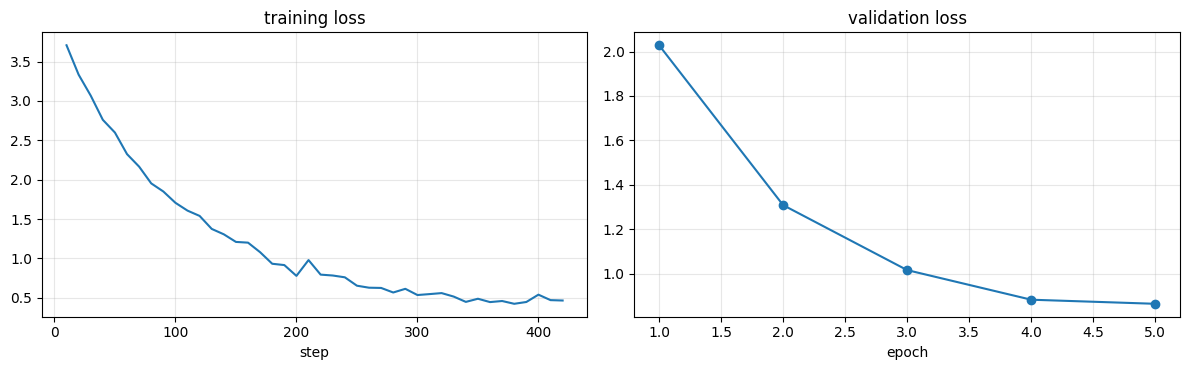

Best checkpoint: /content/llm_faq/checkpoints/checkpoint-420
Saved adapter to /content/llm_faq/lora_adapter -> ['README.md', 'tokenizer_config.json', 'adapter_config.json', 'adapter_model.safetensors', 'tokenizer.json']


In [13]:
# ---- learning curves ----
hist = pd.DataFrame(trainer.state.log_history)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
if "loss" in hist:
    h = hist[hist["loss"].notna()]; ax[0].plot(h["step"], h["loss"]); ax[0].set_title("training loss"); ax[0].set_xlabel("step")
if "eval_loss" in hist:
    h = hist[hist["eval_loss"].notna()]; ax[1].plot(h["epoch"], h["eval_loss"], marker="o"); ax[1].set_title("validation loss"); ax[1].set_xlabel("epoch")
for a in ax: a.grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_training_curves.png", dpi=150); plt.show()
hist.to_csv(f"{OUT_DIR}/training_log.csv", index=False)

# ---- save the final (best-validation-loss) LoRA adapter ----
model.save_pretrained(ADAPTER_DIR); tokenizer.save_pretrained(ADAPTER_DIR)
print("Best checkpoint:", trainer.state.best_model_checkpoint)
print("Saved adapter to", ADAPTER_DIR, "->", os.listdir(ADAPTER_DIR))

## Step 5 – Evaluation (Deliverable 3)
### 5.1 Manual: base vs. fine-tuned on 10 test queries
The *base* model is the **same network with the LoRA adapter switched off**, prompted with the same `Customer: … / Support:` format and the same decoding settings, so the comparison is fair. The queries are written by hand (not copied from the training data); two of them are deliberately out-of-domain / differently phrased. Fill in the two rating columns (1–5) yourself for the report.

In [14]:
MANUAL = [
    ("Can I return a product after 30 days?",              "Returns only within 30 days of delivery"),
    ("How do I track my order?",                            "My Orders > Track / tracking email"),
    ("My package arrived broken, what should I do?",        "Report within 48 h with photo; free replacement/refund"),
    ("Do you ship to Canada?",                              "Yes, 40+ countries, 7-14 business days, customer pays duties"),
    ("I forgot my password, help!",                         "Forgot Password link, reset email"),
    ("Is there free delivery?",                             "Free standard shipping over $50"),
    ("Can I pay with PayPal?",                              "Yes: Visa, MasterCard, Amex, PayPal, Apple Pay, gift card"),
    ("How long will it take to get my money back after a return?", "5-7 business days to original payment method"),
    ("What is the capital of France?",                      "Out of scope -> only orders/shipping/returns/accounts"),
    ("Can I change my delivery address after placing the order?", "Only before it ships, in My Orders"),
]
mq = [q for q, _ in MANUAL]
base_out = generate_answers(model, mq, use_adapter=False)
ft_out   = generate_answers(model, mq, use_adapter=True)

manual_df = pd.DataFrame({"query": mq, "expected_gist": [g for _, g in MANUAL],
                          "base_model": base_out, "fine_tuned": ft_out, "base_rating_1to5": "", "finetuned_rating_1to5": ""})
manual_df.to_csv(f"{OUT_DIR}/manual_evaluation.csv", index=False)
for i, r in manual_df.iterrows():
    print(f"[{i+1}] Q: {r['query']}\n    expected : {r['expected_gist']}\n    BASE     : {r['base_model']}\n    FINE-TUNED: {r['fine_tuned']}\n")

[1] Q: Can I return a product after 30 days?
    expected : Returns only within 30 days of delivery
    BASE     : 
    FINE-TUNED: Items must be unused, in their original packaging and with all tags attached to be eligible for a return.

[2] Q: How do I track my order?
    expected : My Orders > Track / tracking email
    BASE     : 
    FINE-TUNED: We track orders in My Orders until the order ships. Once it has shipped, the tracking details are back in your spam folder.

[3] Q: My package arrived broken, what should I do?
    expected : Report within 48 h with photo; free replacement/refund
    BASE     : 
    FINE-TUNED: We are sorry about that! Report it within 48 hours of delivery with a photo through My Orders and we will send a free replacement or a refund.

[4] Q: Do you ship to Canada?
    expected : Yes, 40+ countries, 7-14 business days, customer pays duties
    BASE     : 
    FINE-TUNED: We deliver to over 50 countries. International delivery takes 3-5 business days.

[5] 

### 5.2 Automated metrics on the held-out test set
Computed on all test questions (paraphrases never seen in training), comparing the generated answer with the reference answer:
* **BLEU** (sacreBLEU, corpus level, 0–100) and **ROUGE-1 / ROUGE-L** (F-measure)
* **Embedding similarity:** mean cosine similarity of `all-MiniLM-L6-v2` sentence embeddings (SentenceTransformers)
* **Perplexity** of the reference answers given the question (lower = the model finds the reference answer more likely)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

generated 81 x 2 answers in 15s


,base model,fine-tuned (LoRA),change
BLEU,0.000,14.704,14.704
ROUGE-1,0.007,0.323,0.316
ROUGE-L,0.006,0.267,0.262
Embedding cosine,0.067,0.517,0.450
Test loss,3.717,0.908,-2.808
Perplexity,41.135,2.480,-38.655


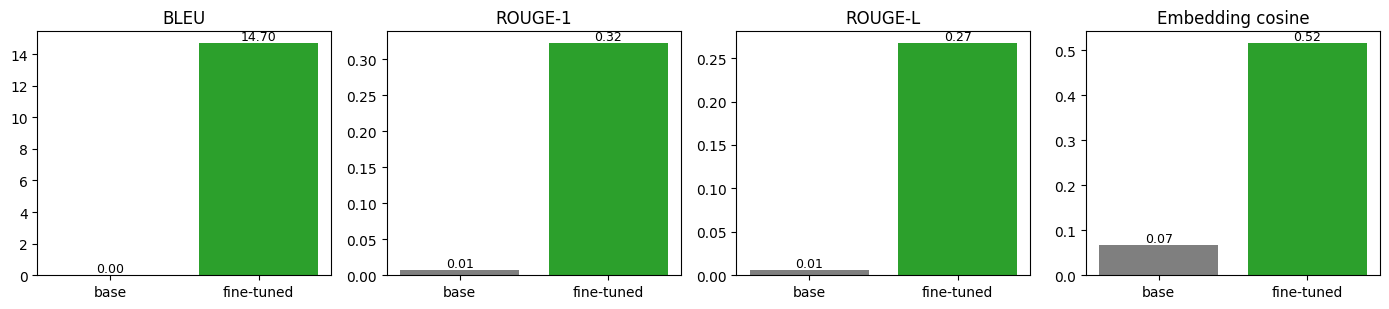

In [15]:
import sacrebleu
from rouge_score import rouge_scorer
from sentence_transformers import SentenceTransformer

rs = rouge_scorer.RougeScorer(["rouge1", "rougeL"], use_stemmer=True)
embedder = SentenceTransformer("all-MiniLM-L6-v2", device=str(device))

def automatic_metrics(hyps, refs):
    bleu = sacrebleu.corpus_bleu(hyps, [refs]).score
    r1 = float(np.mean([rs.score(r, h)["rouge1"].fmeasure for h, r in zip(hyps, refs)]))
    rl = float(np.mean([rs.score(r, h)["rougeL"].fmeasure for h, r in zip(hyps, refs)]))
    eh = embedder.encode(hyps, convert_to_tensor=True, normalize_embeddings=True, batch_size=64)
    er = embedder.encode(refs, convert_to_tensor=True, normalize_embeddings=True, batch_size=64)
    cos = (eh * er).sum(1).cpu().numpy()
    return {"BLEU": bleu, "ROUGE-1": r1, "ROUGE-L": rl, "Embedding cosine": float(cos.mean())}, cos

@torch.no_grad()
def dataset_loss(m, ds, use_adapter=True, bs=16):
    m.eval(); tot, n = 0.0, 0
    ctx = m.disable_adapter() if (not use_adapter and hasattr(m, "disable_adapter")) else contextlib.nullcontext()
    with ctx:
        for i in range(0, len(ds), bs):
            batch = {k: v.to(m.device) for k, v in collate([ds[j] for j in range(i, min(i + bs, len(ds)))]).items()}
            loss = m(**batch).loss.item(); ntok = (batch["labels"][:, 1:] != -100).sum().item()
            tot += loss * ntok; n += ntok
    return tot / n

test_q_list, test_refs = test_df["prompt"].tolist(), test_df["response"].tolist()
t0 = time.time()
test_base = generate_answers(model, test_q_list, use_adapter=False)
test_ft   = generate_answers(model, test_q_list, use_adapter=True)
print(f"generated {len(test_q_list)} x 2 answers in {time.time()-t0:.0f}s")

m_base, cos_base = automatic_metrics(test_base, test_refs)
m_ft,   cos_ft   = automatic_metrics(test_ft,   test_refs)
for nm, ft_flag, dst in (("base", False, m_base), ("ft", True, m_ft)):
    loss = dataset_loss(model, test_ds, use_adapter=ft_flag)
    dst["Test loss"], dst["Perplexity"] = loss, math.exp(loss)

results = pd.DataFrame({"base model": m_base, "fine-tuned (LoRA)": m_ft})
results["change"] = results["fine-tuned (LoRA)"] - results["base model"]
display(results.round(3))
results.round(4).to_csv(f"{OUT_DIR}/automatic_metrics.csv")
json.dump({"base": m_base, "finetuned": m_ft, "n_test": len(test_q_list)}, open(f"{OUT_DIR}/automatic_metrics.json", "w"), indent=2)

names = ["BLEU", "ROUGE-1", "ROUGE-L", "Embedding cosine"]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for a, nm in zip(axes, names):
    a.bar(["base", "fine-tuned"], [m_base[nm], m_ft[nm]], color=["tab:gray", "tab:green"]); a.set_title(nm)
    for i, v in enumerate([m_base[nm], m_ft[nm]]): a.text(i, v, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_metrics_base_vs_ft.png", dpi=150); plt.show()

In [16]:
# ---- qualitative look at the test set: random examples + the weakest fine-tuned answers ----
ex_df = pd.DataFrame({"question": test_q_list, "reference": test_refs, "base": test_base, "fine_tuned": test_ft, "cos_ft": cos_ft})
pd.set_option("display.max_colwidth", 140)
print("Random test examples:"); display(ex_df.sample(6, random_state=3).drop(columns="cos_ft"))
print("\nLowest embedding-similarity fine-tuned answers (candidates for error analysis):")
display(ex_df.sort_values("cos_ft").head(6))
ex_df.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

Random test examples:


,question,reference,base,fine_tuned
12,"Hey, are your products fake or original?","Yes, every product is sourced directly from authorised brands and suppliers, so all items are 100% authentic.",,"Please contact support@shopease.example from your registered email. If the order is not listed, contact support with your order number a..."
17,Where is the size chart?,"Use the Size Guide link beside the size selector on each product page. If you are between two sizes, size up.",,We offer price adjustments within 30 days of purchase. Contact support with your order number and we will refund the difference.
6,Do you have express shipping?,"Yes, express shipping is $12.99 with delivery in 1-2 business days. Orders placed before 2 pm ET ship the same day.",Yes,"Yes, express shipping is available for orders above $50. Express shipping is free for orders above 50 points."
36,can i speak to a human,"Sure, you can reach a human agent through live chat (9 am to 9 pm ET) or by emailing support@shopease.example.",,"Yes, I am the ShopEase support assistant, so I can only answer questions about orders, shipping, returns, payments and accounts."
32,"Hi, which items cannot be returned?","Items marked Final Sale, gift cards and personalised products cannot be returned or exchanged.","Yes, we can.","Items must be unused, in their original packaging and with all tags attached to be eligible for a return."
68,"Hello, can I get a tracking number? Thank you.",Open My Orders and click Track next to your order. A tracking link is also sent to you by email once the order ships.,,"Yes, standard orders can go to a PO box. Express orders require a street address."



Lowest embedding-similarity fine-tuned answers (candidates for error analysis):


,question,reference,base,fine_tuned,cos_ft
71,Do you support 2FA? Thanks!,We support two-factor authentication. Enable it in Account Settings > Security and confirm logins with a code sent to your phone.,Yes!,"Yes, we offer free size and colour exchanges within 30 days of delivery. Choose Exchange Item in My Orders to begin.",0.068622
12,"Hey, are your products fake or original?","Yes, every product is sourced directly from authorised brands and suppliers, so all items are 100% authentic.",,"Please contact support@shopease.example from your registered email. If the order is not listed, contact support with your order number a...",0.145904
38,Can I change the items in my order?,Orders cannot be edited after checkout. Please cancel the order in My Orders before it ships and place a new one.,,"Orders can ship in separate packages from different warehouses, and each package has its own tracking number. You can also download it f...",0.194819
16,"Excuse me, can I change the items in my order? Thank you.",Orders cannot be edited after checkout. Please cancel the order in My Orders before it ships and place a new one.,,"Orders can ship in separate packages from different warehouses, and each package has its own tracking number. You can also download it f...",0.194819
74,"Good morning, how do I get 10% off?",New customers get 10% off their first order with the code WELCOME10 after subscribing to our newsletter.,,"Yes, we offer free size and colour exchanges within 30 days of delivery. Choose Exchange Item in My Orders to begin.",0.199238
67,"Good morning, will my items ship together? Any info would be appreciated.","Orders can ship in separate packages from different warehouses, and each package has its own tracking number. You are not charged extra ...",,"Items must be unused, in their original packaging and with all tags attached to be eligible for a return.",0.230458


## Step 6 – Merge & export the fine-tuned model (optional but handy)
The LoRA adapter (`lora_adapter/`, a few MB) is the main checkpoint. We also create a **merged, stand-alone model** (adapter folded into the base weights) that can be loaded with plain `AutoModelForCausalLM`, and check that it reproduces the adapter's answers.

In [17]:
EXPORT_MERGED = True
if EXPORT_MERGED:
    base_fp = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    merged = PeftModel.from_pretrained(base_fp, ADAPTER_DIR).merge_and_unload()
    merged.save_pretrained(MERGED_DIR); tokenizer.save_pretrained(MERGED_DIR)
    merged.to(device).eval()
    same = generate_answers(merged, mq[:3]) == generate_answers(model, mq[:3], use_adapter=True)
    print("merged model saved to", MERGED_DIR, "| reproduces adapter outputs on 3 queries:", same)
    del merged, base_fp; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/76 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

merged model saved to /content/llm_faq/merged_model | reproduces adapter outputs on 3 queries: True


## Step 7 – Inference script (Deliverable 2): CLI and Gradio
`inference.py` loads the base model + LoRA adapter and supports
* a **single query:** `python inference.py --adapter_dir lora_adapter --query "..."`
* an **interactive CLI** (default)
* a **Gradio** web UI (`--gradio`)

In [18]:
%%writefile /content/llm_faq/outputs/inference.py
#!/usr/bin/env python
"""Inference for the fine-tuned ShopEase FAQ assistant (LoRA adapter on a small causal LM).

Examples
--------
  python inference.py --adapter_dir lora_adapter --query "Can I return a product after 30 days?"
  python inference.py --adapter_dir lora_adapter              # interactive CLI (type 'quit' to exit)
  python inference.py --adapter_dir lora_adapter --gradio     # web UI (pip install gradio)
"""
import argparse

import torch
from peft import PeftConfig, PeftModel
from transformers import AutoModelForCausalLM, AutoTokenizer


def load_model(adapter_dir, base_model=None, device=None):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    base_name = base_model or PeftConfig.from_pretrained(adapter_dir).base_model_name_or_path
    try:
        tokenizer = AutoTokenizer.from_pretrained(adapter_dir)
    except Exception:
        tokenizer = AutoTokenizer.from_pretrained(base_name)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token
    tokenizer.padding_side = "left"
    model = AutoModelForCausalLM.from_pretrained(base_name)
    model = PeftModel.from_pretrained(model, adapter_dir)
    model.to(device).eval()
    return model, tokenizer


def build_prompt(query):
    return f"Customer: {query.strip()}\nSupport:"


@torch.no_grad()
def answer(model, tokenizer, query, max_new_tokens=64):
    enc = tokenizer(build_prompt(query), return_tensors="pt").to(model.device)
    out = model.generate(**enc, max_new_tokens=max_new_tokens, do_sample=False, num_beams=1,
                         no_repeat_ngram_size=4, use_cache=True, pad_token_id=tokenizer.eos_token_id)
    text = tokenizer.decode(out[0, enc["input_ids"].shape[1]:], skip_special_tokens=True)
    return text.split("\n")[0].strip()


def main():
    ap = argparse.ArgumentParser(description=__doc__, formatter_class=argparse.RawDescriptionHelpFormatter)
    ap.add_argument("--adapter_dir", default="lora_adapter", help="folder with the saved LoRA adapter")
    ap.add_argument("--base_model", default=None, help="override the base model name stored in the adapter")
    ap.add_argument("--query", default=None, help="single question; prints the answer and exits")
    ap.add_argument("--gradio", action="store_true", help="launch a Gradio web interface")
    ap.add_argument("--max_new_tokens", type=int, default=64)
    args = ap.parse_args()

    model, tokenizer = load_model(args.adapter_dir, args.base_model)

    if args.query:
        print(answer(model, tokenizer, args.query, args.max_new_tokens))
    elif args.gradio:
        import gradio as gr
        demo = gr.Interface(
            fn=lambda q: answer(model, tokenizer, q, args.max_new_tokens),
            inputs=gr.Textbox(label="Customer question", lines=2),
            outputs=gr.Textbox(label="ShopEase assistant"),
            title="ShopEase customer-support assistant (fine-tuned small LLM)",
            examples=["Can I return a product after 30 days?", "How do I track my order?", "Do you ship to Canada?"])
        demo.launch(share=True)
    else:
        print("ShopEase assistant - type a customer question ('quit' to exit)")
        while True:
            q = input("Customer> ").strip()
            if q.lower() in {"quit", "exit", "q"}:
                break
            if q:
                print("Support>", answer(model, tokenizer, q, args.max_new_tokens))


if __name__ == "__main__":
    main()

Writing /content/llm_faq/outputs/inference.py


In [19]:
# test the CLI script end-to-end in a fresh process
for q in ["Can I return a product after 30 days?", "Where can I find my invoice?"]:
    r = subprocess.run([sys.executable, f"{OUT_DIR}/inference.py", "--adapter_dir", ADAPTER_DIR, "--query", q],
                       capture_output=True, text=True)
    print("Q:", q, "\nA:", r.stdout.strip().splitlines()[-1] if r.stdout.strip() else r.stderr[-500:], "\n")

Q: Can I return a product after 30 days? 
A: Items must be unused, in their original packaging and with all tags attached to be eligible for a return. 

Q: Where can I find my invoice? 
A: We email the invoice together with your order confirmation. You can also download it from My Orders. 



In [20]:
# Optional Gradio demo (public share link appears below; set RUN_GRADIO = False to skip)
RUN_GRADIO = True
if RUN_GRADIO:
    import gradio as gr
    def respond(q): return generate_answers(model, [q])[0]
    demo = gr.Interface(fn=respond,
                        inputs=gr.Textbox(label="Customer question", lines=2),
                        outputs=gr.Textbox(label="ShopEase assistant"),
                        title="ShopEase customer-support assistant (fine-tuned DistilGPT-2 + LoRA)",
                        examples=[["Can I return a product after 30 days?"], ["How do I track my order?"], ["Do you ship to Canada?"]])
    demo.launch(share=True, debug=False)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://ece05633a80e124556.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## Step 8 – README draft and packaging (Deliverable 4)
Generates a `README.md` pre-filled with the dataset statistics, training setup, metrics and sample outputs from this run. **Edit the "Challenges & limitations" section with your own observations** before submitting. Finally everything is zipped for download (and optionally copied to Google Drive).

In [21]:
def md_table(frame):
    try:    return frame.to_markdown(index=False)
    except Exception: return "```\n" + frame.to_string(index=False) + "\n```"

best_val = float(hist["eval_loss"].min()) if "eval_loss" in hist else float("nan")
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
readme = f"""# Fine-Tuning a Small LLM for Customer-Support FAQs

## 1. Dataset
* Domain: e-commerce support for a fictional store (ShopEase); {len(raw_df)} synthetic Q&A pairs from 56 policy topics (returns, refunds, shipping, payments, accounts, promotions, warranty, ...).
* Format: JSONL `{{"prompt": ..., "response": ...}}`; cleaned (Unicode normalisation, whitespace, length filter, de-duplication) -> {len(df)} pairs.
* Split 80/10/10 grouped by question (paraphrases never cross splits): train {len(train_df)}, val {len(val_df)}, test {len(test_df)}.

## 2. Model and training setup
* Base model: `{MODEL_NAME}` ({n_params/1e6:.0f} M parameters) + LoRA (r={LORA_R}, alpha={LORA_ALPHA}, dropout={LORA_DROPOUT}); trainable parameters: {trainable/1e6:.2f} M.
* Prompt format `Customer: <q>\\nSupport: <a><eos>`; loss on answer tokens only.
* Hugging Face `Trainer`, {EPOCHS} epochs max, batch size {BATCH_SIZE}, lr {LR} (cosine), fp16, early stopping (patience {PATIENCE}) on validation loss; best validation loss {best_val:.3f}.
* Quantisation setting: {QUANT}. Hardware: {torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'}.

## 3. Results (test set, {len(test_df)} questions)
{md_table(results.round(3).reset_index().rename(columns={'index': 'metric'}))}

## 4. Sample outputs (base vs fine-tuned)
{md_table(manual_df[['query', 'base_model', 'fine_tuned']].head(5))}

Full 10-query comparison: `manual_evaluation.csv`.

## 5. Challenges & limitations (edit this section)
* The dataset is synthetic and template-based, so test questions are paraphrases of training topics; scores on real customer traffic would be lower.
* A very small model (82 M) can still produce fluent but wrong details; answers should be checked against the policy before use.
* Out-of-domain questions are handled only through the few examples in the dataset.
* (add your own observations: training time, overfitting behaviour, failure cases from `test_predictions.csv`, ...)

## 6. Usage
`python inference.py --adapter_dir lora_adapter --query "Can I return a product after 30 days?"` (or `--gradio`).
"""
open(f"{OUT_DIR}/README.md", "w", encoding="utf-8").write(readme)
shutil.copy(DATA_PATH, f"{OUT_DIR}/ecommerce_faqs.jsonl")
shutil.copy("build_ecommerce_faq_dataset.py", f"{OUT_DIR}/build_ecommerce_faq_dataset.py")
print(readme[:1800], "\n...")

# Fine-Tuning a Small LLM for Customer-Support FAQs

## 1. Dataset
* Domain: e-commerce support for a fictional store (ShopEase); 837 synthetic Q&A pairs from 56 policy topics (returns, refunds, shipping, payments, accounts, promotions, warranty, ...).
* Format: JSONL `{"prompt": ..., "response": ...}`; cleaned (Unicode normalisation, whitespace, length filter, de-duplication) -> 837 pairs.
* Split 80/10/10 grouped by question (paraphrases never cross splits): train 671, val 85, test 81.

## 2. Model and training setup
* Base model: `distilgpt2` (82 M parameters) + LoRA (r=32, alpha=64, dropout=0.05); trainable parameters: 2.36 M.
* Prompt format `Customer: <q>\nSupport: <a><eos>`; loss on answer tokens only.
* Hugging Face `Trainer`, 5 epochs max, batch size 8, lr 0.0005 (cosine), fp16, early stopping (patience 2) on validation loss; best validation loss 0.864.
* Quantisation setting: None. Hardware: Tesla T4.

## 3. Results (test set, 81 questions)
| metric           |   base model |

In [22]:
STAGE = "/content/llm_faq_stage"                       # zip everything except the large merged model
shutil.rmtree(STAGE, ignore_errors=True)
shutil.copytree(WORK, STAGE, ignore=shutil.ignore_patterns("merged_model"))
zip_path = shutil.make_archive("/content/llm_faq_deliverables", "zip", STAGE)
print("created", zip_path, f"({os.path.getsize(zip_path)/1e6:.1f} MB)")
print("top level:", sorted(os.listdir(STAGE)))
print("outputs  :", sorted(os.listdir(f"{STAGE}/outputs")))

SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    shutil.copytree(WORK, "/content/drive/MyDrive/llm_faq", dirs_exist_ok=True); print("copied to Drive")
try:
    from google.colab import files
    files.download(zip_path)
except Exception as e:
    print("download manually from the file panel:", zip_path)

created /content/llm_faq_deliverables.zip (61.9 MB)
top level: ['checkpoints', 'data', 'lora_adapter', 'outputs']
outputs  : ['README.md', 'automatic_metrics.csv', 'automatic_metrics.json', 'build_ecommerce_faq_dataset.py', 'ecommerce_faqs.jsonl', 'fig_dataset_lengths.png', 'fig_metrics_base_vs_ft.png', 'fig_training_curves.png', 'inference.py', 'manual_evaluation.csv', 'test_predictions.csv', 'training_log.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
### ✅ Done – what to hand in
`llm_faq_deliverables.zip` contains: `data/` (cleaned JSONL + splits), `checkpoints/`, `lora_adapter/`, `outputs/inference.py`, metrics CSV/JSON, figures, `manual_evaluation.csv`, `README.md` (edit the *Challenges & limitations* section), plus this notebook. (The 330 MB `merged_model/` folder stays in `/content/llm_faq/` and is left out of the zip; copy it to Drive with `SAVE_TO_DRIVE = True` if you need it.)

**Ideas to experiment with:** `QUANT="4bit"` with `MODEL_NAME="facebook/opt-125m"`, larger `LORA_R`, different learning rates, or replacing the synthetic data with a real FAQ corpus (same JSONL format).